In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
data = pd.read_csv("Wholesale customers data.csv")

features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X = data[features]

print("Original Dataset:")
print(X.head())
print("\nOriginal Dimensions:", X.shape)

Original Dataset:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185

Original Dimensions: (440, 6)


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [5]:
pca_df = pd.DataFrame(X_pca, columns=["Principal Component 1", "Principal Component 2"])

print("\nReduced Dataset:")
print(pca_df.head())
print("\nReduced Dimensions:", X_pca.shape)


Reduced Dataset:
   Principal Component 1  Principal Component 2
0               0.193291              -0.305100
1               0.434420              -0.328413
2               0.811143               0.815096
3              -0.778648               0.652754
4               0.166287               1.271434

Reduced Dimensions: (440, 2)


In [6]:
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)
print("\nTotal Variance Preserved:", sum(pca.explained_variance_ratio_))


Explained Variance Ratio:
[0.44082893 0.283764  ]

Total Variance Preserved: 0.7245929240774496


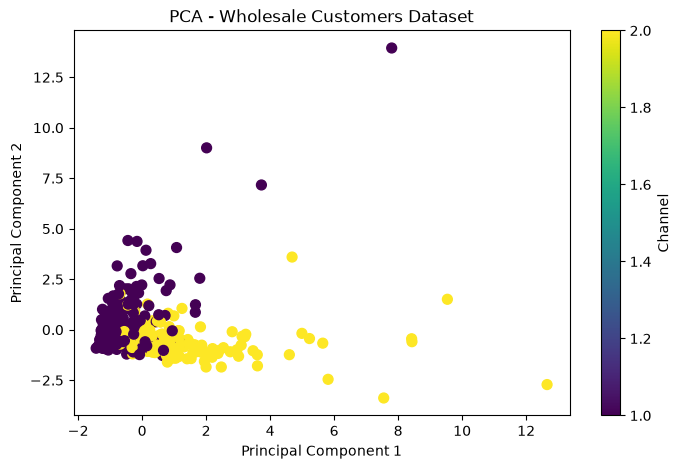

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data["Channel"], cmap="viridis", s=50)
plt.title("PCA - Wholesale Customers Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Channel")
plt.show()